In [ ]:
# Librerías necesarias
!pip install transformers datasets torch pandas matplotlib seaborn

In [ ]:
import pandas as pd

train_nb15= pd.read_csv('/content/UNSW_NB15_training-set.csv')
test_nb15 = pd.read_csv('/content/UNSW_NB15_testing-set.csv')

# Verificar Registros
train_nb15['label'].value_counts()
train_nb15['attack_cat'].value_counts()

,count
attack_cat,
Normal,56000
Generic,40000
Exploits,33393
Fuzzers,18184
DoS,12264
Reconnaissance,10491
Analysis,2000
Backdoor,1746
Shellcode,1133


In [ ]:
# ==== Semillas para reproducibilidad ====
import os, random, numpy as np, torch
from transformers import set_seed

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# para que cuDNN no cambie heurísticas entre ejecuciones
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# utilidad de transformers (afecta generadores internos)
set_seed(SEED)
# =======================================

print("✅ Reproducibilidad configurada (SEED = 42)")
print(f"📊 Registros de entrenamiento: {train_nb15.shape[0]}")
print(f"📊 Registros de prueba: {test_nb15.shape[0]}")
train_nb15.head()


✅ Reproducibilidad configurada (SEED = 42)
📊 Registros de entrenamiento: 175341
📊 Registros de prueba: 82332


,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


In [ ]:
# === dataset completo (dataset ya preprocesado y limpio) ===
train_df_full = train_nb15.copy()
test_df_full  = test_nb15.copy()

# Construcción de la secuencia textual (proto + service + state)
train_df_full['text'] = train_df_full['proto'] + " " + train_df_full['service'] + " " + train_df_full['state']
test_df_full['text']  = test_df_full['proto']  + " " + test_df_full['service']  + " " + test_df_full['state']

# Visualizar ejemplos generados
print("📝 Ejemplos de secuencias de texto para RoBERTa:")
display(train_df_full[['proto', 'service', 'state', 'text']].sample(3))


📝 Ejemplos de secuencias de texto para RoBERTa:


,proto,service,state,text
15482,tcp,-,FIN,tcp - FIN
133349,udp,dns,INT,udp dns INT
80485,tcp,-,FIN,tcp - FIN


In [ ]:
# === Reducir entrenamiento con muestra estratificada y balanceada por 'label' ===

def balanced_by_label(df, label_col, max_total, random_state):
    vc = df[label_col].value_counts()
    clases = vc.index.tolist()
    per_class = max_total // len(clases)

    partes = []
    for c in clases:
        n = min(per_class, int(vc[c]))
        partes.append(df[df[label_col] == c].sample(n=n, replace=False, random_state=random_state))

    out = pd.concat(partes, axis=0).sample(frac=1.0, random_state=random_state).reset_index(drop=True)
    return out

# Ajusta max_total
train_df_full = balanced_by_label(train_df_full, label_col='label', max_total=35_000, random_state=SEED)



In [ ]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_NAME = "roberta-large"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_NAME, num_labels=2)

MAX_LEN= 16
train_encodings_roberta = tokenizer(
    list(train_df_full['text']),
    truncation=True,
    padding='max_length',
    max_length=MAX_LEN,
    return_tensors="pt"
)

test_encodings_roberta = tokenizer(
    list(test_df_full['text']),
    truncation=True,
    padding='max_length',
    max_length=MAX_LEN,
    return_tensors="pt"
)

print("✅ Tokenización finalizada. Ready to fine-tune RoBERTa.")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/1.42G [00:00<?, ?B/s]

Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at roberta-large and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


✅ Tokenización finalizada. Ready to fine-tune RoBERTa.


In [ ]:
from torch.utils.data import Dataset, DataLoader
import torch

class TextClsDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, idx):
        item = {k: torch.tensor(v[idx], dtype=torch.long) for k, v in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

train_dataset = TextClsDataset(train_encodings_roberta, list(train_df_full['label']))
test_dataset  = TextClsDataset(test_encodings_roberta,  list(test_df_full['label']))

g = torch.Generator(); g.manual_seed(SEED)  # para reproducibilidad en el shuffle
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, generator=g)
test_loader  = DataLoader(test_dataset,  batch_size=16)

print("✅ DataLoaders listos")
print("Batches de entrenamiento:", len(train_loader))
print("Batches de prueba:", len(test_loader))

✅ DataLoaders listos
Batches de entrenamiento: 2188
Batches de prueba: 5146


In [ ]:
from torch import nn
from torch.optim import AdamW
from transformers import get_scheduler
from tqdm import tqdm

# === Configuración de entrenamiento ===
EPOCHS = 5
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
MAX_GRAD_NORM = 1.0

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

# === Optimizer y Scheduler con warmup ===
optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

total_steps = len(train_loader) * EPOCHS
scheduler = get_scheduler(
    name="linear",
    optimizer=optimizer,
    num_warmup_steps=int(0.1 * total_steps),  # 10% warmup
    num_training_steps=total_steps
)

# === Función de pérdida
criterion = nn.CrossEntropyLoss()

# === Entrenamiento
for epoch in range(EPOCHS):
    model.train()
    total_loss = 0
    loop = tqdm(train_loader, desc=f"🚀 Epoch {epoch+1}/{EPOCHS}", leave=False)

    for batch in loop:
        batch = {k: v.to(device) for k, v in batch.items()}

        outputs = model(**batch)
        loss = outputs.loss
        loss.backward()

        # Clipping de gradientes
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=MAX_GRAD_NORM)

        optimizer.step()
        scheduler.step()
        optimizer.zero_grad()

        total_loss += loss.item()
        loop.set_postfix(loss=loss.item())

    avg_loss = total_loss / len(train_loader)
    print(f"✅ Época {epoch+1} completada – Loss promedio: {avg_loss:.4f}")


🚀 Epoch 1/3:   0%|          | 0/2188 [00:00<?, ?it/s]/tmp/ipython-input-3324289171.py:11: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  item = {k: torch.tensor(v[idx], dtype=torch.long) for k, v in self.encodings.items()}


KeyboardInterrupt: 

In [ ]:
model.save_pretrained("./roberta_ids_model")
tokenizer.save_pretrained("./roberta_ids_model")


('./roberta_ids_model/tokenizer_config.json',
 './roberta_ids_model/special_tokens_map.json',
 './roberta_ids_model/vocab.json',
 './roberta_ids_model/merges.txt',
 './roberta_ids_model/added_tokens.json',
 './roberta_ids_model/tokenizer.json')

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np, seaborn as sns, matplotlib.pyplot as plt
import torch

model.eval()

# === Accuracy simple ===
correct, total = 0, 0
with torch.no_grad():
    for batch in test_loader:
        out = model(
            batch['input_ids'].to(device),
            attention_mask=batch['attention_mask'].to(device)
        )
        preds = torch.argmax(out.logits, dim=1)
        correct += (preds.cpu() == batch['labels']).sum().item()
        total   += batch['labels'].size(0)

acc = correct / total
print(f"📊 Precisión (accuracy) en UNSW-NB15: {acc:.2%}")

# === Reporte detallado + matriz de confusión ===
all_preds, all_labels = [], []

with torch.no_grad():
    for batch in test_loader:
        out = model(
            batch['input_ids'].to(device),
            attention_mask=batch['attention_mask'].to(device)
        )
        probs = torch.softmax(out.logits, dim=-1)
        preds = (probs[:,1] >= 0.5).long()  # Umbral ajustado a 0.5
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(batch['labels'].cpu().numpy())

# === Classification report ===
print("\n📈 Reporte de métricas:")
print(classification_report(
    all_labels,
    all_preds,
    target_names=['Normal', 'Ataque'],
    digits=2,
    zero_division=0
))

# === Matriz de confusión ===
cm = confusion_matrix(all_labels, all_preds, labels=[0,1])

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal','Ataque'], yticklabels=['Normal','Ataque'])
plt.xlabel('Predicción')
plt.ylabel('Real')
plt.title('Matriz de Confusión')
plt.show()


/tmp/ipython-input-3324289171.py:11: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  item = {k: torch.tensor(v[idx], dtype=torch.long) for k, v in self.encodings.items()}


KeyboardInterrupt: 

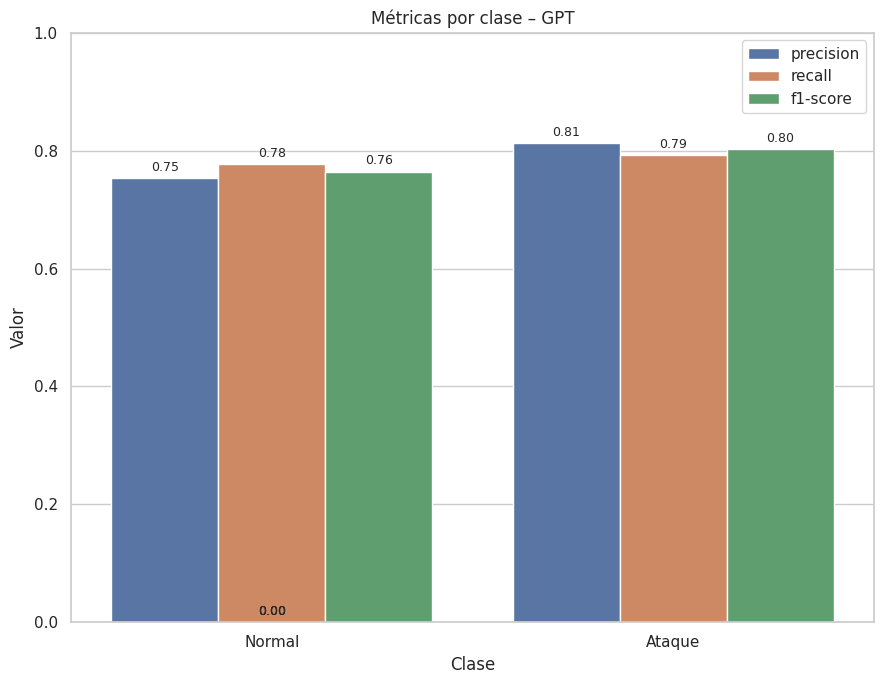

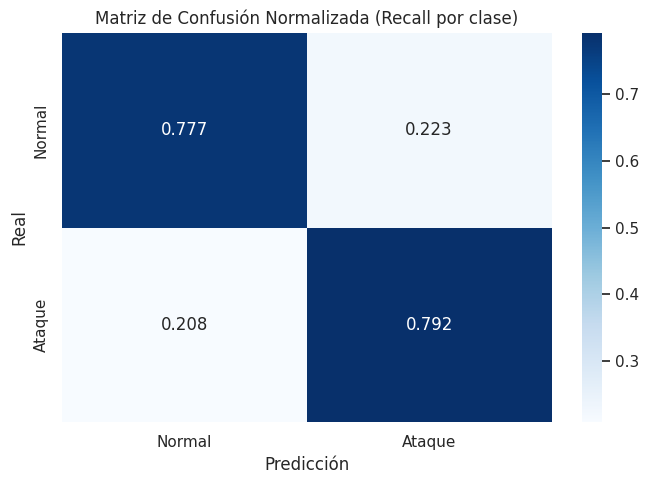

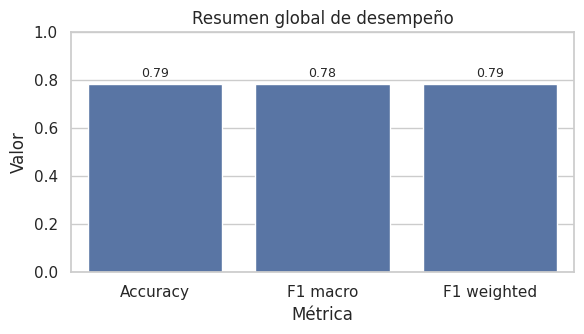

In [ ]:
# Requiere: all_labels, all_preds (del bloque anterior)
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid")

# ===== 1) Barras por clase: precision / recall / F1 (valores en decimales) =====
rep = classification_report(
    all_labels, all_preds,
    target_names=['Normal','Ataque'],
    output_dict=True, zero_division=0
)
df_metrics = pd.DataFrame(rep).T  # filas: Normal, Ataque, accuracy, macro avg, weighted avg
classes = ['Normal','Ataque']
plot_df = df_metrics.loc[classes, ['precision','recall','f1-score']].reset_index().rename(columns={'index':'Clase'})
plot_df = plot_df.melt(id_vars='Clase', var_name='Métrica', value_name='Valor')

plt.figure(figsize=(9,7))
ax = sns.barplot(data=plot_df, x='Clase', y='Valor', hue='Métrica')
ax.set_ylim(0,1)
ax.set_title('Métricas por clase – RoBERTa')
ax.set_ylabel('Valor')

# Etiquetas en cada barra (decimales)
for p in ax.patches:
    val = p.get_height()
    ax.annotate(f'{val:.2f}',
                (p.get_x() + p.get_width()/2., val),
                ha='center', va='bottom', fontsize=9, xytext=(0,3), textcoords='offset points')
ax.legend(title='', loc='upper right')
plt.tight_layout()
plt.show()

# ===== 2) Matriz de confusión normalizada (decimales, recall por clase) =====
cm = confusion_matrix(all_labels, all_preds, labels=[0,1])
cm_norm = cm.astype(np.float64) / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(7,5))
ax = sns.heatmap(cm_norm, annot=True, fmt='.3f', cmap='Blues',
                 xticklabels=['Normal','Ataque'], yticklabels=['Normal','Ataque'])
ax.set_xlabel('Predicción'); ax.set_ylabel('Real')
ax.set_title('Matriz de Confusión Normalizada (Recall por clase)')
plt.tight_layout()
plt.show()

# ===== 3) Resumen global: accuracy, F1 macro, F1 weighted (decimales) =====
acc = accuracy_score(all_labels, all_preds)
f1_macro  = df_metrics.loc['macro avg','f1-score']
f1_weight = df_metrics.loc['weighted avg','f1-score']

summary_df = pd.DataFrame({
    'Métrica': ['Accuracy','F1 macro','F1 weighted'],
    'Valor':   [acc, f1_macro, f1_weight]
})

plt.figure(figsize=(6,3.5))
ax = sns.barplot(data=summary_df, x='Métrica', y='Valor')
ax.set_ylim(0,1)
ax.set_title('Resumen global de desempeño')

for p in ax.patches:
    val = p.get_height()
    ax.annotate(f'{val:.2f}',
                (p.get_x() + p.get_width()/2., val),
                ha='center', va='bottom', fontsize=9, xytext=(0,3), textcoords='offset points')
plt.tight_layout()
plt.show()

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


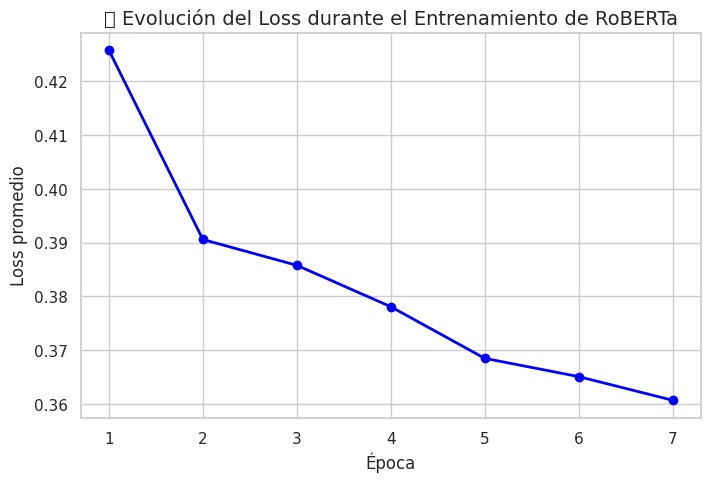

In [ ]:
import matplotlib.pyplot as plt

# Valores de pérdida por época (los que reportaste)
loss_values = [0.4258, 0.3906, 0.3858, 0.3781, 0.3685, 0.3651, 0.3607]

plt.figure(figsize=(8,5))
plt.plot(range(1, 8), loss_values, marker='o', linestyle='-', color='blue', linewidth=2)
plt.title("📉 Evolución del Loss durante el Entrenamiento de RoBERTa", fontsize=14)
plt.xlabel("Época", fontsize=12)
plt.ylabel("Loss promedio", fontsize=12)
plt.grid(True)
plt.xticks(range(1, 8))
plt.show()


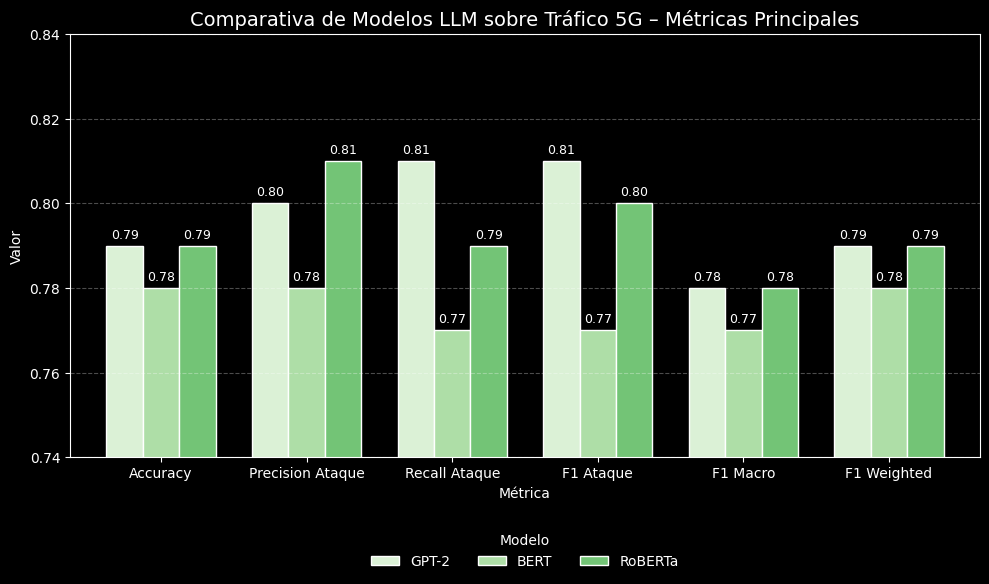

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Activar fondo negro
plt.style.use('dark_background')

# Datos
data = {
    'Modelo': ['GPT-2', 'BERT', 'RoBERTa'],
    'Accuracy': [0.79, 0.78, 0.79],
    'Precision Ataque': [0.80, 0.78, 0.81],
    'Recall Ataque': [0.81, 0.77, 0.79],
    'F1 Ataque': [0.81, 0.77, 0.80],
    'F1 Macro': [0.78, 0.77, 0.78],
    'F1 Weighted': [0.79, 0.78, 0.79]
}

df = pd.DataFrame(data)
df = df.set_index('Modelo').T

# Paleta original de azules
palette = sns.color_palette("Greens", n_colors=5)

# Crear figura
fig, ax = plt.subplots(figsize=(10, 6))
df.plot(kind='bar', width=0.75, rot=0, color=palette, ax=ax, edgecolor='white')

# Añadir valores en las barras
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height:.2f}',
                (p.get_x() + p.get_width() / 2., height + 0.001),
                ha='center', va='bottom', fontsize=9, color='white')

# Títulos y etiquetas
ax.set_title("Comparativa de Modelos LLM sobre Tráfico 5G – Métricas Principales", fontsize=14, color='white')
ax.set_ylabel("Valor", color='white')
ax.set_xlabel("Métrica", color='white')
ax.set_ylim(0.74, 0.84)

# Ajuste de ticks y ejes
ax.tick_params(axis='x', colors='white')
ax.tick_params(axis='y', colors='white')
ax.grid(axis='y', linestyle='--', alpha=0.3)

# Leyenda corregida
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False, labelcolor='white', title_fontsize=10, title="Modelo")

plt.tight_layout()
plt.show()


In [ ]:
import torch, numpy as np
from transformers import RobertaForSequenceClassification, RobertaTokenizer

# Ruta a tu modelo ya fine-tuned
MODEL_DIR = "./roberta_ids_model"

# Cargar modelo y tokenizer desde carpeta local (sin reentrenar)
tokenizer = RobertaTokenizer.from_pretrained(MODEL_DIR, local_files_only=True)
model = RobertaForSequenceClassification.from_pretrained(MODEL_DIR, local_files_only=True)

model.eval()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

# Nombres de clases según tu configuración (ajústalo si tu orden es distinto)
CLASS_NAMES = ["Normal", "Ataque"]

# Función de predicción para usar con SHAP/LIME (recibe str o list[str])
def f_predict(texts, max_length=128):
    if isinstance(texts, str):
        texts = [texts]
    elif not isinstance(texts, list):
        texts = list(texts)  # p.ej. Series/ndarray

    texts = [str(t) for t in texts]

    enc = tokenizer(
        texts,
        return_tensors="pt",
        padding=True,
        truncation=True,
        max_length=max_length
    ).to(device)

    with torch.no_grad():
        logits = model(**enc).logits
        probs = torch.nn.functional.softmax(logits, dim=1).detach().cpu().numpy()  # (n, 2)
    return probs





OSError: Can't load tokenizer for './roberta_ids_model'. If you were trying to load it from 'https://huggingface.co/models', make sure you don't have a local directory with the same name. Otherwise, make sure './roberta_ids_model' is the correct path to a directory containing all relevant files for a RobertaTokenizer tokenizer.

In [ ]:
import shap

# Masker basado en el tokenizador de HF (mejor que regex para ver subpalabras/tokens BPE)
masker = shap.maskers.Text(tokenizer)

# Explainer: usa tu función de predicción y fija nombres de salida
explainer = shap.Explainer(f_predict, masker, output_names=CLASS_NAMES)


PartitionExplainer explainer: 81it [00:12,  1.14it/s]


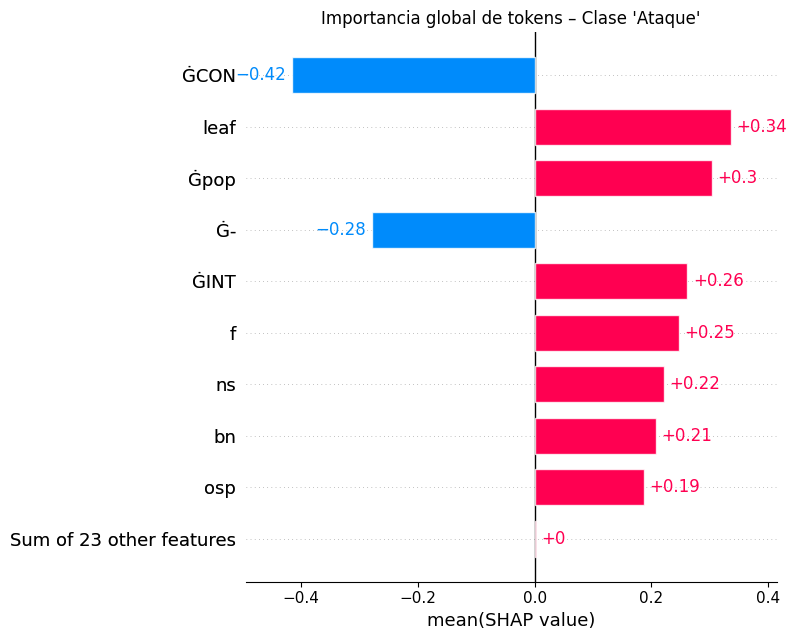

In [ ]:
import matplotlib.pyplot as plt

# Si no lo tienes calculado, crea un subconjunto
subset = test_df_full["text"].astype(str).sample(80, random_state=123).tolist()
sv_batch = explainer(subset)

# Bar plot global para clase 1 = "Ataque"
plt.figure(figsize=(7, 4))
shap.plots.bar(sv_batch.mean(axis=0)[:, 1], show=False)
plt.title("Importancia global de tokens – Clase 'Ataque'")
plt.tight_layout()
plt.savefig("shap_global_importance_ataque.png", dpi=300)
plt.show()



In [ ]:
%pip install lime


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 12.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=a4f1dd45d392e5df9b7ae9930c2aea44e50e4620912de5acc78f3fb45107b91e
  Stored in directory: /root/.cache/pip/wheels/e7/5d/0e/4b4fff9a47468fed5633211fb3b76d1db43fe806a17fb7486a
Successfully built lime


In [ ]:
from lime.lime_text import LimeTextExplainer

lime_explainer = LimeTextExplainer(class_names=CLASS_NAMES)

# LIME llama a una función que devuelva probs en (n, n_clases)
lime_exp = lime_explainer.explain_instance(
    sample_text,
    f_predict,
    num_features=10
)

# Mostrar en notebook
lime_exp.show_in_notebook(text=True)



In [ ]:
%pip install bertviz


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 157.5/157.5 kB 11.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 139.3/139.3 kB 13.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.0/14.0 MB 126.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 85.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.7/85.7 kB 7.9 MB/s eta 0:00:00


In [ ]:
from bertviz import head_view

sample_text = "tcp http SF"

# Preparar inputs
inputs = tokenizer(sample_text, return_tensors="pt")
input_ids = inputs["input_ids"].to(device)
attention_mask = inputs["attention_mask"].to(device)

# Ejecutar el modelo pidiendo atenciones
with torch.no_grad():
    outputs = model(
        input_ids=input_ids,
        attention_mask=attention_mask,
        output_attentions=True
    )

attentions = [a.detach().cpu() for a in outputs.attentions]
tokens = tokenizer.convert_ids_to_tokens(input_ids[0])

# Mostrar visualización interactiva en Jupyter/Colab
head_view(attentions, tokens)




<IPython.core.display.Javascript object>